Import libraries and load saved work

In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "2"
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from threadpoolctl import threadpool_limits
from sklearn.metrics import mean_absolute_error

ROOT = Path(".")
if not (ROOT / "prepared_data").exists() and Path("../prepared_data").exists():
    ROOT = Path("..")
if not (ROOT / "model_outputs/forecast_bundle.joblib").exists():
    raise FileNotFoundError("Run Steps 1 and 2 first, or update ROOT.")
data = joblib.load(ROOT / "prepared_data/model_data.joblib")
forecast = joblib.load(ROOT / "model_outputs/forecast_bundle.joblib")
with open(ROOT / "model_outputs/model_summary.json", encoding="utf-8") as file:
    model_summary = json.load(file)
OUTPUT_DIR = ROOT / "monitoring_outputs"
OUTPUT_DIR.mkdir(exist_ok=True)
FEATURES = forecast["feature_columns"]
pd.set_option("display.max_columns", 12)

def predict_bill(inputs, bundle=forecast):
    inputs = inputs[FEATURES]
    if bundle["use_baseline"]:
        result = inputs[bundle["baseline_column"]].to_numpy()
    else:
        with threadpool_limits(limits=2):
            result = bundle["pipeline"].predict(inputs)
    return np.maximum(np.asarray(result, dtype=float), 0)

print("Frozen predictor:", forecast["recommended_name"])
print("Model training targets end:", model_summary["validation_target_end"])

Frozen predictor: HistGradientBoosting 250
Model training targets end: 2025-02-01


Fix the monitoring rules before evaluating them

In [2]:
NOMINAL_COVERAGE = 0.90
RELATIVE_INCREASE = 0.20
MINIMUM_INCREASE = 50.0
VOLATILITY_MULTIPLIER = 2.0
MINIMUM_HISTORY = 3
SCALE_FLOOR = 1.0

def history_threshold(inputs):
    average = inputs["bill_mean_3"].to_numpy(dtype=float)
    variability = inputs["bill_std_3"].fillna(0).to_numpy(dtype=float)
    margin = np.maximum.reduce([
        RELATIVE_INCREASE * average,
        np.full(len(inputs), MINIMUM_INCREASE),
        VOLATILITY_MULTIPLIER * variability,
    ])
    return average + margin

def interval_scale(inputs):
    return np.maximum(inputs["bill_mean_3"].to_numpy(dtype=float), SCALE_FLOOR)

test_inputs = data["X_test"].reset_index(drop=True)
test_metadata = data["test_metadata"].reset_index(drop=True)
test_actual = data["y_test"].to_numpy()
test_prediction = predict_bill(test_inputs)
assert (test_metadata["forecast_month"] > pd.Timestamp(model_summary["validation_target_end"])).all()
assert np.isfinite(test_inputs[["bill_mean_3", "history_months"]]).all().all()
assert (test_inputs["bill_mean_3"] >= 0).all()
print("High-bill rules are fixed. The predictor is unchanged.")

High-bill rules are fixed. The predictor is unchanged.


Use the first later month to calibrate the range

In [3]:
forecast_months = sorted(test_metadata["forecast_month"].unique())
if len(forecast_months) < 2:
    raise ValueError("Need separate calibration and later evaluation months.")
calibration_month = pd.Timestamp(forecast_months[0])
calibration_mask = test_metadata["forecast_month"].eq(calibration_month).to_numpy()
evaluation_mask = test_metadata["forecast_month"].gt(calibration_month).to_numpy()
assert not np.any(calibration_mask & evaluation_mask)
assert test_metadata.loc[calibration_mask, "forecast_month"].max() < test_metadata.loc[evaluation_mask, "forecast_month"].min()

relative_errors = (
    np.abs(test_actual[calibration_mask] - test_prediction[calibration_mask])
    / interval_scale(test_inputs.loc[calibration_mask])
)
sample_count = len(relative_errors)
quantile_rank = int(np.ceil((sample_count + 1) * NOMINAL_COVERAGE))
if quantile_rank > sample_count:
    raise ValueError("Not enough calibration rows for this coverage level.")
relative_allowance = float(np.sort(relative_errors)[quantile_rank - 1])
print("Calibration forecast month:", calibration_month.date())
print("Calibration rows:", sample_count)
print("Later evaluation rows:", int(evaluation_mask.sum()))
print(f"Relative error allowance: {relative_allowance:.2%}")

Calibration forecast month: 2025-03-01
Calibration rows: 1000
Later evaluation rows: 2000
Relative error allowance: 27.05%


Build customer monitoring rows
- High-bill alert: point prediction exceeds the history threshold.
- Strong alert: even the lower end of the range exceeds the threshold.
- Possible high bill: the upper end exceeds the threshold, but the point prediction does not. This is a wider watchlist.
- Within range: the upper end stays below the threshold.

In [4]:
def make_monitoring_table(inputs, metadata, allowance):
    inputs = inputs.reset_index(drop=True)
    result = metadata.reset_index(drop=True).copy()
    prediction = predict_bill(inputs)
    width = allowance * interval_scale(inputs)
    result["predicted_next_bill"] = prediction
    result["estimated_lower_bill"] = np.maximum(0, prediction - width)
    result["estimated_upper_bill"] = prediction + width
    result["nominal_coverage"] = NOMINAL_COVERAGE
    result["recent_average"] = inputs["bill_mean_3"].to_numpy()
    result["recent_std"] = inputs["bill_std_3"].fillna(0).to_numpy()
    result["high_bill_threshold"] = history_threshold(inputs)
    result["sufficient_history"] = inputs["history_months"].ge(MINIMUM_HISTORY).to_numpy()
    result["predicted_increase"] = prediction - result["recent_average"]
    result["predicted_increase_percent"] = (
        100 * result["predicted_increase"] / result["recent_average"].replace(0, np.nan))
    result["high_bill_alert"] = result["sufficient_history"] & (prediction > result["high_bill_threshold"])
    result["strong_alert"] = result["sufficient_history"] & (result["estimated_lower_bill"] > result["high_bill_threshold"])
    result["possible_high_bill"] = result["sufficient_history"] & (result["estimated_upper_bill"] > result["high_bill_threshold"])
    result["priority"] = np.select(
        [~result["sufficient_history"], result["strong_alert"], result["high_bill_alert"], result["possible_high_bill"]],
        ["History review", "Strong alert", "High-bill alert", "Possible high bill"], default="Within range")
    result["estimated_excess"] = np.maximum(0, prediction - result["high_bill_threshold"])
    result["possible_excess"] = np.maximum(0, result["estimated_upper_bill"] - result["high_bill_threshold"])
    return result

all_test_monitoring = make_monitoring_table(test_inputs, test_metadata, relative_allowance)
evaluation = all_test_monitoring.loc[evaluation_mask].reset_index(drop=True)
evaluation["actual_next_bill"] = test_actual[evaluation_mask]
evaluation["actual_high_bill"] = evaluation["actual_next_bill"] > evaluation["high_bill_threshold"]
evaluation["inside_estimated_range"] = (
    evaluation["actual_next_bill"].ge(evaluation["estimated_lower_bill"])
    & evaluation["actual_next_bill"].le(evaluation["estimated_upper_bill"]))
display(evaluation.head().round(2))

,customer_id,billing_month,forecast_month,plan_type,bill_amount,bill_mean_3,...,priority,estimated_excess,possible_excess,actual_next_bill,actual_high_bill,inside_estimated_range
0,C00001,2025-03-01,2025-04-01,Standard,474.36,472.00,...,Possible high bill,0.0,41.14,441.32,False,True
1,C00001,2025-04-01,2025-05-01,Standard,441.32,462.17,...,Possible high bill,0.0,39.92,444.27,False,True
2,C00002,2025-03-01,2025-04-01,Basic,234.82,215.15,...,Possible high bill,0.0,23.34,234.82,False,True
3,C00002,2025-04-01,2025-05-01,Basic,234.82,234.82,...,Possible high bill,0.0,23.78,253.70,False,True
4,C00003,2025-03-01,2025-04-01,Basic,646.51,648.75,...,Possible high bill,0.0,80.30,803.36,True,True


Measure the estimated range

,segment,rows,coverage_percent,mean_interval_width,MAE
0,Overall,2000,88.35,285.429,51.162


,segment,group,rows,coverage_percent,mean_interval_width,MAE
0,plan_type,Basic,822,74.939,233.429,76.626
1,plan_type,Premium,350,100.000,446.619,28.862
2,plan_type,Standard,828,96.739,268.915,35.308
3,forecast_month,2025-04-01 00:00:00,1000,87.700,283.978,51.431
4,forecast_month,2025-05-01 00:00:00,1000,89.000,286.879,50.892


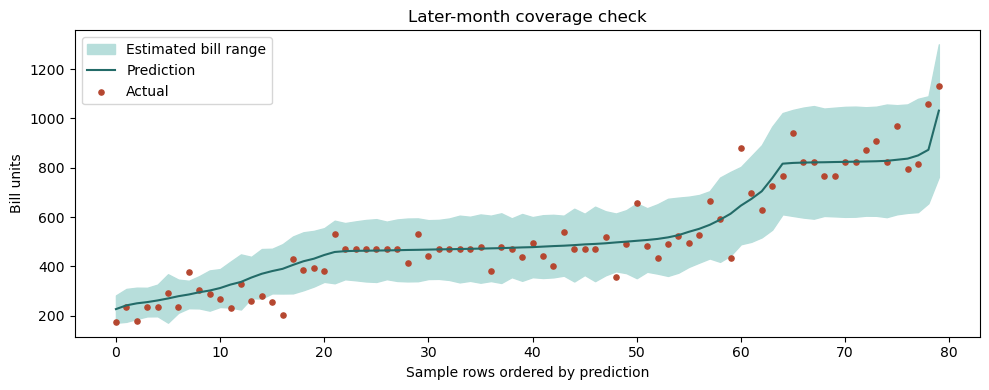

In [5]:
def interval_metrics(table):
    return {
        "rows": len(table),
        "coverage_percent": 100 * table["inside_estimated_range"].mean(),
        "mean_interval_width": (table["estimated_upper_bill"] - table["estimated_lower_bill"]).mean(),
        "MAE": mean_absolute_error(table["actual_next_bill"], table["predicted_next_bill"]),
    }

overall_interval = interval_metrics(evaluation)
display(pd.DataFrame([{"segment": "Overall", **overall_interval}]).round(3))
interval_rows = []
for column in ["plan_type", "forecast_month"]:
    for group, part in evaluation.groupby(column, observed=True):
        interval_rows.append({"segment": column, "group": str(group), **interval_metrics(part)})
interval_by_group = pd.DataFrame(interval_rows)
display(interval_by_group.round(3))

sample = evaluation.sort_values("predicted_next_bill").iloc[::max(1, len(evaluation)//80)]
fig, ax = plt.subplots(figsize=(10, 4))
positions = np.arange(len(sample))
ax.fill_between(positions, sample["estimated_lower_bill"], sample["estimated_upper_bill"], color="#b7dedb", label="Estimated bill range")
ax.plot(positions, sample["predicted_next_bill"], color="#236b68", label="Prediction")
ax.scatter(positions, sample["actual_next_bill"], s=14, color="#b54730", label="Actual")
ax.set(xlabel="Sample rows ordered by prediction", ylabel="Bill units", title="Later-month coverage check")
ax.legend()
plt.tight_layout()
plt.show()

Evaluate alert quality, including missed high bills

In [6]:
eligible = evaluation.loc[evaluation["sufficient_history"]].copy()

def alert_metrics(table, flag_column):
    actual = table["actual_high_bill"].to_numpy(dtype=bool)
    flagged = table[flag_column].to_numpy(dtype=bool)
    tp = int(np.sum(flagged & actual))
    fp = int(np.sum(flagged & ~actual))
    fn = int(np.sum(~flagged & actual))
    tn = int(np.sum(~flagged & ~actual))
    return {
        "rows": len(table), "flagged_rows": tp + fp, "actual_high_rows": tp + fn,
        "true_positive": tp, "false_positive": fp, "false_negative": fn, "true_negative": tn,
        "precision_percent": 100 * tp / (tp + fp) if tp + fp else np.nan,
        "recall_percent": 100 * tp / (tp + fn) if tp + fn else np.nan,
        "F1": 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else np.nan,
        "review_workload_percent": 100 * (tp + fp) / len(table) if len(table) else np.nan,
    }

alert_rows = []
for column, label in [("high_bill_alert", "Point-prediction alert"),
                      ("possible_high_bill", "Upper-range watchlist")]:
    alert_rows.append({"rule": label, **alert_metrics(eligible, column)})
alert_quality = pd.DataFrame(alert_rows)
display(alert_quality.round(3))
alert_segment_rows = []
for plan, part in eligible.groupby("plan_type", observed=True):
    for flag in ["high_bill_alert", "possible_high_bill"]:
        alert_segment_rows.append({"plan_type": plan, "rule": flag, **alert_metrics(part, flag)})
alert_by_plan = pd.DataFrame(alert_segment_rows)
display(alert_by_plan.round(3))
display(eligible.loc[eligible["actual_high_bill"] & ~eligible["high_bill_alert"],
                     ["customer_id", "forecast_month", "predicted_next_bill", "actual_next_bill", "high_bill_threshold"]].head(10).round(2))
point_quality = alert_rows[0]
watch_quality = alert_rows[1]
print(f"Point alerts found {point_quality['true_positive']} of {point_quality['actual_high_rows']} actual high bills.")
print(f"The wider watchlist found {watch_quality['true_positive']}, while flagging {watch_quality['review_workload_percent']:.1f}% of eligible rows.")
if point_quality["recall_percent"] < 20:
    print("Point forecasts missed most high bills in these months. Sudden-spike detection remains a limitation.")
if watch_quality["review_workload_percent"] > 50:
    print("The upper-range watchlist requires review of most rows. Its broad coverage comes with many false alarms.")

,rule,rows,flagged_rows,actual_high_rows,true_positive,false_positive,false_negative,true_negative,precision_percent,recall_percent,F1,review_workload_percent
0,Point-prediction alert,2000,9,174,5,4,169,1822,55.556,2.874,0.055,0.45
1,Upper-range watchlist,2000,1494,174,157,1337,17,489,10.509,90.230,0.188,74.70


,plan_type,rule,rows,flagged_rows,actual_high_rows,true_positive,...,false_negative,true_negative,precision_percent,recall_percent,F1,review_workload_percent
0,Basic,high_bill_alert,822,9,124,5,...,119,694,55.556,4.032,0.075,1.095
1,Basic,possible_high_bill,822,472,124,110,...,14,336,23.305,88.710,0.369,57.421
2,Premium,high_bill_alert,350,0,2,0,...,2,348,NaN,0.000,0.000,0.000
3,Premium,possible_high_bill,350,343,2,2,...,0,7,0.583,100.000,0.012,98.000
4,Standard,high_bill_alert,828,0,48,0,...,48,780,NaN,0.000,0.000,0.000
5,Standard,possible_high_bill,828,679,48,45,...,3,146,6.627,93.750,0.124,82.005


,customer_id,forecast_month,predicted_next_bill,actual_next_bill,high_bill_threshold
4,C00003,2025-04-01,683.29,803.36,778.50
13,C00007,2025-05-01,656.43,770.22,761.59
25,C00013,2025-05-01,549.09,706.29,672.63
27,C00014,2025-05-01,560.28,839.91,767.43
38,C00020,2025-04-01,576.82,758.02,670.66
49,C00025,2025-05-01,538.80,723.53,608.55
64,C00033,2025-04-01,307.86,462.20,310.27
73,C00037,2025-05-01,520.99,565.15,563.30
76,C00039,2025-04-01,575.51,641.89,595.65
92,C00047,2025-04-01,647.33,865.83,713.02


Point alerts found 5 of 174 actual high bills.
The wider watchlist found 157, while flagging 74.7% of eligible rows.
Point forecasts missed most high bills in these months. Sudden-spike detection remains a limitation.
The upper-range watchlist requires review of most rows. Its broad coverage comes with many false alarms.


Explain predictions with grouped feature comparisons

In [7]:
FEATURE_GROUPS = {
    "Plan and pricing": ["plan_type", "plan_fee", "discount_amount"],
    "Current usage": ["data_usage_gb", "voice_calls", "sms_count", "addon_data_gb"],
    "Current charges and bill": ["data_charge", "voice_charge", "addon_charge", "tax_amount", "bill_amount", "extra_charges"],
    "Bill history": ["bill_lag_1", "bill_lag_2", "bill_mean_3", "bill_std_3", "bill_change_1"],
    "Usage history": ["usage_mean_3", "usage_change_1"],
    "Recorded history and month": ["history_months", "forecast_month_sin", "forecast_month_cos"],
}
grouped_columns = [column for columns in FEATURE_GROUPS.values() for column in columns]
assert len(grouped_columns) == len(set(grouped_columns))
assert set(grouped_columns) == set(FEATURES)

development_inputs = pd.concat([data["X_train"], data["X_validation"]], ignore_index=True)
reference_rows = []
for plan, part in development_inputs.groupby("plan_type", observed=True):
    reference_index = (part["bill_amount"] - part["bill_amount"].median()).abs().idxmin()
    reference_rows.append(part.loc[reference_index, FEATURES])
references = pd.DataFrame(reference_rows).set_index("plan_type", drop=False)
display(references[["plan_type", "bill_amount", "bill_mean_3"]].reset_index(drop=True).round(2))

def explain_customer_groups(inputs, reference_table=references):
    inputs = inputs[FEATURES].reset_index(drop=True)
    unknown = set(inputs["plan_type"].dropna()) - set(reference_table.index)
    if unknown or inputs["plan_type"].isna().any():
        raise ValueError("A plan has no reference record. Review the input plan names.")
    working = reference_table.loc[inputs["plan_type"].tolist(), FEATURES].reset_index(drop=True).copy()
    reference_prediction = predict_bill(working)
    previous = reference_prediction.copy()
    contributions = pd.DataFrame(index=inputs.index)
    for group, columns in FEATURE_GROUPS.items():
        working[columns] = inputs[columns]
        current = predict_bill(working)
        contributions[group] = current - previous
        previous = current
    np.testing.assert_allclose(reference_prediction + contributions.sum(axis=1), predict_bill(inputs), atol=1e-6)
    return reference_prediction, contributions

def add_driver_text(table, reference_prediction, contributions):
    result = table.reset_index(drop=True).copy()
    result["reference_prediction"] = reference_prediction
    for rank in range(1, 4):
        result[f"driver_{rank}"] = ""
    for position, values in contributions.iterrows():
        top_groups = values.abs().nlargest(3).index
        for rank, group in enumerate(top_groups, start=1):
            result.at[position, f"driver_{rank}"] = f"{group}: {values[group]:+.2f} bill units vs reference"
    return result

,plan_type,bill_amount,bill_mean_3
0,Basic,367.47,249.54
1,Premium,824.82,810.07
2,Standard,470.82,470.82


Build and prioritize the latest customer view

In [8]:
latest_inputs = data["X_latest"].reset_index(drop=True)
latest_metadata = data["latest_metadata"].reset_index(drop=True)
latest_table = make_monitoring_table(latest_inputs, latest_metadata, relative_allowance)
reference_prediction, latest_contributions = explain_customer_groups(latest_inputs)
latest_table = add_driver_text(latest_table, reference_prediction, latest_contributions)

PRIORITY_ORDER = {"Strong alert": 0, "High-bill alert": 1, "History review": 2,
                  "Possible high bill": 3, "Within range": 4}
latest_table["priority_order"] = latest_table["priority"].map(PRIORITY_ORDER)
latest_table["suggested_review"] = latest_table["priority"].map({
    "Strong alert": "Review recent usage and charges promptly.",
    "High-bill alert": "Review usage, add-ons and current plan before contacting the customer.",
    "History review": "Collect more billing history before relying on an automatic alert.",
    "Possible high bill": "Monitor usage; the estimated upper range exceeds the history threshold.",
    "Within range": "Continue routine monitoring.",
})
prioritized_customers = latest_table.sort_values(
    ["priority_order", "estimated_excess", "possible_excess"], ascending=[True, False, False]).reset_index(drop=True)
view_columns = ["customer_id", "forecast_month", "plan_type", "predicted_next_bill",
                "estimated_lower_bill", "estimated_upper_bill", "recent_average", "high_bill_threshold",
                "priority", "driver_1"]
display(prioritized_customers[view_columns].head(15).round(2))
display(prioritized_customers["priority"].value_counts().rename("customers").to_frame())

,customer_id,forecast_month,plan_type,predicted_next_bill,estimated_lower_bill,estimated_upper_bill,recent_average,high_bill_threshold,priority,driver_1
0,C00626,2025-06-01,Basic,237.79,192.37,283.21,167.90,217.90,High-bill alert,Bill history: -24.26 bill units vs reference
1,C00102,2025-06-01,Basic,272.98,215.92,330.04,210.90,260.90,High-bill alert,Current usage: +34.32 bill units vs reference
2,C00403,2025-06-01,Basic,240.25,192.69,287.82,175.82,234.82,High-bill alert,Bill history: -26.91 bill units vs reference
3,C00581,2025-06-01,Basic,955.08,714.85,1195.30,887.96,1065.56,Possible high bill,Bill history: +577.02 bill units vs reference
4,C00758,2025-06-01,Basic,990.95,739.66,1242.23,928.83,1114.60,Possible high bill,Bill history: +644.88 bill units vs reference
5,C00934,2025-06-01,Basic,820.66,618.73,1022.59,746.42,895.70,Possible high bill,Bill history: +466.80 bill units vs reference
6,C00556,2025-06-01,Basic,1088.90,807.12,1370.67,1041.55,1249.86,Possible high bill,Bill history: +734.35 bill units vs reference
7,C00120,2025-06-01,Standard,902.56,674.06,1131.06,844.62,1013.54,Possible high bill,Bill history: +311.52 bill units vs reference
8,C00075,2025-06-01,Premium,870.80,650.78,1090.82,813.27,975.93,Possible high bill,Current usage: +28.92 bill units vs reference
9,C00925,2025-06-01,Premium,816.53,612.01,1021.05,755.99,907.18,Possible high bill,Plan and pricing: +10.95 bill units vs reference


,customers
priority,
Possible high bill,707
Within range,290
High-bill alert,3


Inspect one customer's explanation

,value
customer_id,C00626
plan,Basic
predicted_bill,237.79
estimated_range,192.37 to 283.21
recent_average,167.9
threshold,217.9
priority,High-bill alert
reference_prediction,237.57


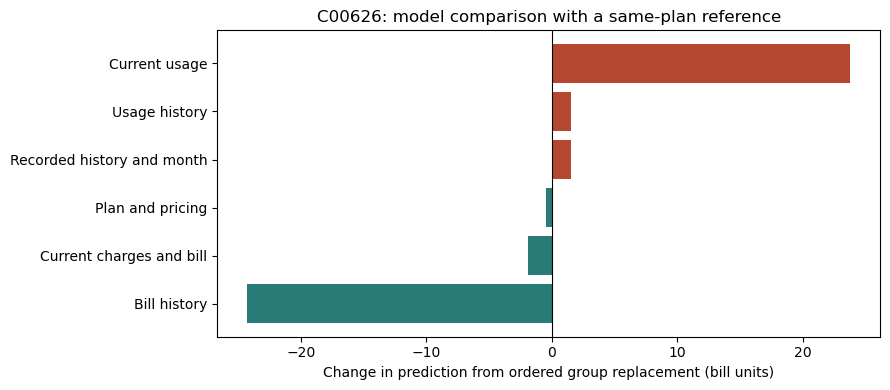

Reference 237.57 + contributions 0.22 = prediction 237.79


In [9]:
CUSTOMER_ID = prioritized_customers.iloc[0]["customer_id"]
matches = np.flatnonzero(latest_metadata["customer_id"].eq(CUSTOMER_ID).to_numpy())
if not len(matches):
    raise ValueError("Customer not found in the latest month.")
position = int(matches[0])
customer = latest_table.iloc[position]
display(pd.Series({
    "customer_id": CUSTOMER_ID, "plan": customer["plan_type"],
    "predicted_bill": round(customer["predicted_next_bill"], 2),
    "estimated_range": f"{customer['estimated_lower_bill']:.2f} to {customer['estimated_upper_bill']:.2f}",
    "recent_average": round(customer["recent_average"], 2),
    "threshold": round(customer["high_bill_threshold"], 2),
    "priority": customer["priority"],
    "reference_prediction": round(customer["reference_prediction"], 2),
}).rename("value").to_frame())

contributions = latest_contributions.iloc[position].sort_values()
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(contributions.index, contributions.values,
        color=["#b54730" if value > 0 else "#287b76" for value in contributions])
ax.axvline(0, color="black", linewidth=0.8)
ax.set(xlabel="Change in prediction from ordered group replacement (bill units)",
       title=f"{CUSTOMER_ID}: model comparison with a same-plan reference")
plt.tight_layout()
plt.show()
print(f"Reference {customer['reference_prediction']:.2f} + contributions {contributions.sum():.2f} = prediction {customer['predicted_next_bill']:.2f}")

Save the monitoring outputs and settings

In [10]:
def clean_json(value):
    if isinstance(value, dict):
        return {key: clean_json(item) for key, item in value.items()}
    if isinstance(value, list):
        return [clean_json(item) for item in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if np.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    return value

settings = {
    "nominal_coverage": NOMINAL_COVERAGE, "relative_allowance": relative_allowance,
    "scale_floor": SCALE_FLOOR, "relative_increase": RELATIVE_INCREASE,
    "minimum_increase": MINIMUM_INCREASE, "volatility_multiplier": VOLATILITY_MULTIPLIER,
    "minimum_history": MINIMUM_HISTORY,
}
monitoring_bundle = {
    "forecast_bundle": forecast, "settings": settings, "reference_rows": references,
    "feature_groups": FEATURE_GROUPS,
    "calibration_forecast_month": str(calibration_month.date()),
    "model_training_target_end": model_summary["validation_target_end"],
}
joblib.dump(monitoring_bundle, OUTPUT_DIR / "monitoring_bundle.joblib")
prioritized_customers.to_csv(OUTPUT_DIR / "latest_customer_monitoring.csv", index=False)
evaluation.to_csv(OUTPUT_DIR / "later_month_monitoring_evaluation.csv", index=False)
interval_by_group.to_csv(OUTPUT_DIR / "interval_metrics_by_group.csv", index=False)
alert_quality.to_csv(OUTPUT_DIR / "alert_quality.csv", index=False)
alert_by_plan.to_csv(OUTPUT_DIR / "alert_quality_by_plan.csv", index=False)
driver_export = pd.concat([
    latest_metadata[["customer_id", "forecast_month"]], latest_contributions,
], axis=1)
driver_export["reference_prediction"] = reference_prediction
driver_export.to_csv(OUTPUT_DIR / "latest_group_contributions.csv", index=False)
calibration_export = test_metadata.loc[calibration_mask, ["customer_id", "forecast_month"]].copy()
calibration_export["actual_next_bill"] = test_actual[calibration_mask]
calibration_export["predicted_next_bill"] = test_prediction[calibration_mask]
calibration_export["relative_absolute_error"] = relative_errors
calibration_export.to_csv(OUTPUT_DIR / "interval_calibration_errors.csv", index=False)

summary = {
    "model": forecast["recommended_name"], "settings": settings,
    "calibration_month": str(calibration_month.date()), "calibration_rows": sample_count,
    "evaluation_start": str(evaluation["forecast_month"].min().date()),
    "evaluation_end": str(evaluation["forecast_month"].max().date()),
    "interval_evaluation": overall_interval,
    "alert_evaluation": alert_quality.to_dict(orient="records"),
    "latest_forecast_month": str(latest_metadata["forecast_month"].max().date()),
    "latest_priority_counts": prioritized_customers["priority"].value_counts().to_dict(),
    "explanation_method": "Ordered grouped replacements from same-plan pre-test reference records",
    "limitations": [
        "Synthetic data; future performance and currency are not established.",
        "Nominal coverage is empirical; repeated customers and drift limit formal coverage claims.",
        "March-May had prior point evaluation in Step 2; this is an additional historical check.",
        "Three-bill history is a short baseline; alert thresholds are illustrative policy choices.",
        "Point forecasts may miss sudden spikes; report recall and watchlist workload.",
        "Customer contributions depend on group order and reference and are not causal tariff effects.",
        "Latest forecasts are unscored because independently verified next bills are unavailable.",
    ],
}
with open(OUTPUT_DIR / "monitoring_summary.json", "w", encoding="utf-8") as file:
    json.dump(clean_json(summary), file, indent=2, allow_nan=False)
print("Monitoring outputs saved to:", OUTPUT_DIR.resolve())

Monitoring outputs saved to: C:\Users\saipr\OneDrive\Desktop\HCL\monitoring_outputs


Reload and verify the reusable results

In [11]:
reloaded = joblib.load(OUTPUT_DIR / "monitoring_bundle.joblib")
np.testing.assert_allclose(predict_bill(latest_inputs, reloaded["forecast_bundle"]), latest_table["predicted_next_bill"])
assert reloaded["settings"] == settings
assert (latest_table["estimated_lower_bill"] <= latest_table["predicted_next_bill"]).all()
assert (latest_table["estimated_upper_bill"] >= latest_table["predicted_next_bill"]).all()
assert (latest_table["estimated_lower_bill"] >= 0).all()
assert latest_table["strong_alert"].le(latest_table["high_bill_alert"]).all()
assert latest_table["high_bill_alert"].le(latest_table["possible_high_bill"]).all()
assert sum(alert_quality.iloc[0][name] for name in ["true_positive", "false_positive", "false_negative", "true_negative"]) == len(eligible)
np.testing.assert_allclose(reference_prediction + latest_contributions.sum(axis=1), latest_table["predicted_next_bill"], atol=1e-6)
saved_customers = pd.read_csv(OUTPUT_DIR / "latest_customer_monitoring.csv")
assert saved_customers["customer_id"].tolist() == prioritized_customers["customer_id"].tolist()
np.testing.assert_allclose(saved_customers["predicted_next_bill"], prioritized_customers["predicted_next_bill"])
# Verify that the predictor still matches the Step 2 test forecasts.
old_test = pd.read_csv(ROOT / "model_outputs/test_predictions.csv")
assert old_test["customer_id"].tolist() == test_metadata["customer_id"].tolist()
np.testing.assert_allclose(old_test["predicted_next_bill"], test_prediction)
print("All reload, accounting, alignment and frozen-model checks passed.")
print(f"Later empirical coverage: {overall_interval['coverage_percent']:.2f}% (nominal {100*NOMINAL_COVERAGE:.0f}%)")
print("Latest customers:", len(prioritized_customers))
display(alert_quality[["rule", "flagged_rows", "actual_high_rows", "precision_percent", "recall_percent"]].round(2))


All reload, accounting, alignment and frozen-model checks passed.
Later empirical coverage: 88.35% (nominal 90%)
Latest customers: 1000


,rule,flagged_rows,actual_high_rows,precision_percent,recall_percent
0,Point-prediction alert,9,174,55.56,2.87
1,Upper-range watchlist,1494,174,10.51,90.23
